In [1]:
import numpy as np
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
import pathlib
from cloudvolume import CloudVolume
import networkx as nx
from tqdm.auto import tqdm

/Users/mateljk1/Documents/projects/aplbrain/zebrafish-pencilsdown/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
xs = [6550, 7056]
ys = [3389 + 1000, 4070 + 1000]
zs = [4974 + 1000 - 100, 4974 + 1000 + 100]

CKPT_CLOUDPATH_STEM = (
    "precomputed://s3://cvdb-bossdb-boss/smith2024/zebrafish/agglomeration_checkpoint_"
)
COMPONENT_PATH = pathlib.Path("./component-graphs/")
cv_channels = [
    CKPT_CLOUDPATH_STEM + str(fname).split(".")[-2]
    for fname in sorted(COMPONENT_PATH.glob("*.gexf"))
]
svol = CloudVolume(
    "precomputed://s3://cvdb-bossdb-boss/smith2024/zebrafish/supervoxels"
)

In [3]:
xs, ys, zs

([6550, 7056], [4389, 5070], [5874, 6074])

In [4]:
def count_contact_voxels(segmentation):
    segment_ids = np.unique(segmentation)
    contact_counts = {i: {j: 0 for j in segment_ids if j != i} for i in segment_ids}

    # Loop over all pairs of segment IDs, creating a mask for each segment and
    # counting the number of voxels that are in contact between the two masks.
    # "Contact" here is defined by shifting the mask in all cardinal directions
    # and taking the union of the shifted masks with the unshifted.
    #
    # In one dimension, that looks like this:
    #
    # i_mask = [0, 0, 1, 1, 0, 0, 0, 0, 0, 0]
    # j_mask = [0, 0, 0, 0, 1, 1, 0, 0, 0, 0]
    #
    # Right shift j-mask:
    # i_mask = [0, 0, 1, 1, 0, 0, 0, 0, 0, 0]
    # j_mask = [0, 0, 0, 0, 0, 0, 1, 1, 0, 0]
    # Union of the two is 0.
    #
    # Left shift j-mask:
    # i_mask = [0, 0, 1, 1, 0, 0, 0, 0, 0, 0]
    # j_mask = [0, 0, 0, 1, 1, 0, 0, 0, 0, 0]
    #                    ^
    # Union of the two is 1.
    # Thus, 0+1 = 1 contact voxel.
    for i in tqdm(segment_ids):
        i_mask = segmentation == i
        # 0-pad the mask so that we can roll it in all directions
        i_mask = np.pad(i_mask, 1, mode="constant", constant_values=0)
        for j in segment_ids:
            if i != j:
                j_mask = segmentation == j
                j_mask = np.pad(j_mask, 1, mode="constant", constant_values=0)
                contact_counts[i][j] = np.sum(
                    i_mask & np.roll(j_mask, 1, axis=0)
                    | i_mask & np.roll(j_mask, -1, axis=0)
                    | i_mask & np.roll(j_mask, 1, axis=1)
                    | i_mask & np.roll(j_mask, -1, axis=1)
                    | i_mask & np.roll(j_mask, 1, axis=2)
                    | i_mask & np.roll(j_mask, -1, axis=2)
                )
    return contact_counts


def count_contact_voxels_parallel(segmentation, n_jobs):
    segment_ids = np.unique(segmentation)
    contact_counts = {i: {j: 0 for j in segment_ids if j != i} for i in segment_ids}

    def process_segment(i):
        i_mask = segmentation == i
        i_mask = np.pad(i_mask, 1, mode="constant", constant_values=0)
        local_contact_counts = {j: 0 for j in segment_ids if j != i}
        for j in segment_ids:
            if i != j:
                j_mask = segmentation == j
                j_mask = np.pad(j_mask, 1, mode="constant", constant_values=0)
                local_contact_counts[int(j)] = int(
                    np.sum(
                        i_mask & np.roll(j_mask, 1, axis=0)
                        | i_mask & np.roll(j_mask, -1, axis=0)
                        | i_mask & np.roll(j_mask, 1, axis=1)
                        | i_mask & np.roll(j_mask, -1, axis=1)
                        | i_mask & np.roll(j_mask, 1, axis=2)
                        | i_mask & np.roll(j_mask, -1, axis=2)
                    )
                )
        return i, local_contact_counts

    results = Parallel(n_jobs=n_jobs)(
        delayed(process_segment)(i) for i in tqdm(segment_ids)
    )

    for i, local_contact_counts in results:
        contact_counts[int(i)] = local_contact_counts

    return contact_counts

In [5]:
def contactome_from_contact_area(results, ignore_labels=None):
    ignore_labels = ignore_labels or [0]

    G = nx.Graph()
    for k, v in results.items():
        for k2, v2 in v.items():
            if v2 > 0:
                G.add_edge(k, k2, weight=v2)

    for i in ignore_labels:
        G.remove_node(i)

    return G

In [6]:
DOWNSAMPLE_FACTOR = 4
contactomes = {}
for cv_channel in cv_channels:
    complete_dlf = CloudVolume(cv_channel)[
        xs[0] : xs[1] : 2 * DOWNSAMPLE_FACTOR,
        ys[0] : ys[1] : 2 * DOWNSAMPLE_FACTOR,
        zs[0] : zs[1] : 1 * DOWNSAMPLE_FACTOR,
        0,
    ]
    G = contactome_from_contact_area(
        count_contact_voxels_parallel(
            complete_dlf,
            -1,
        )
    )
    contactomes[cv_channel] = G

100%|██████████| 945/945 [02:18<00:00,  6.84it/s]


In [7]:
contactomes[
    "precomputed://s3://cvdb-bossdb-boss/smith2024/zebrafish/agglomeration_checkpoint_0"
] = contactome_from_contact_area(
    count_contact_voxels_parallel(
        svol[
            xs[0] : xs[1] : 2 * DOWNSAMPLE_FACTOR,
            ys[0] : ys[1] : 2 * DOWNSAMPLE_FACTOR,
            zs[0] : zs[1] : 1 * DOWNSAMPLE_FACTOR,
            0,
        ], -1
    )
)

100%|██████████| 947/947 [02:21<00:00,  6.70it/s]


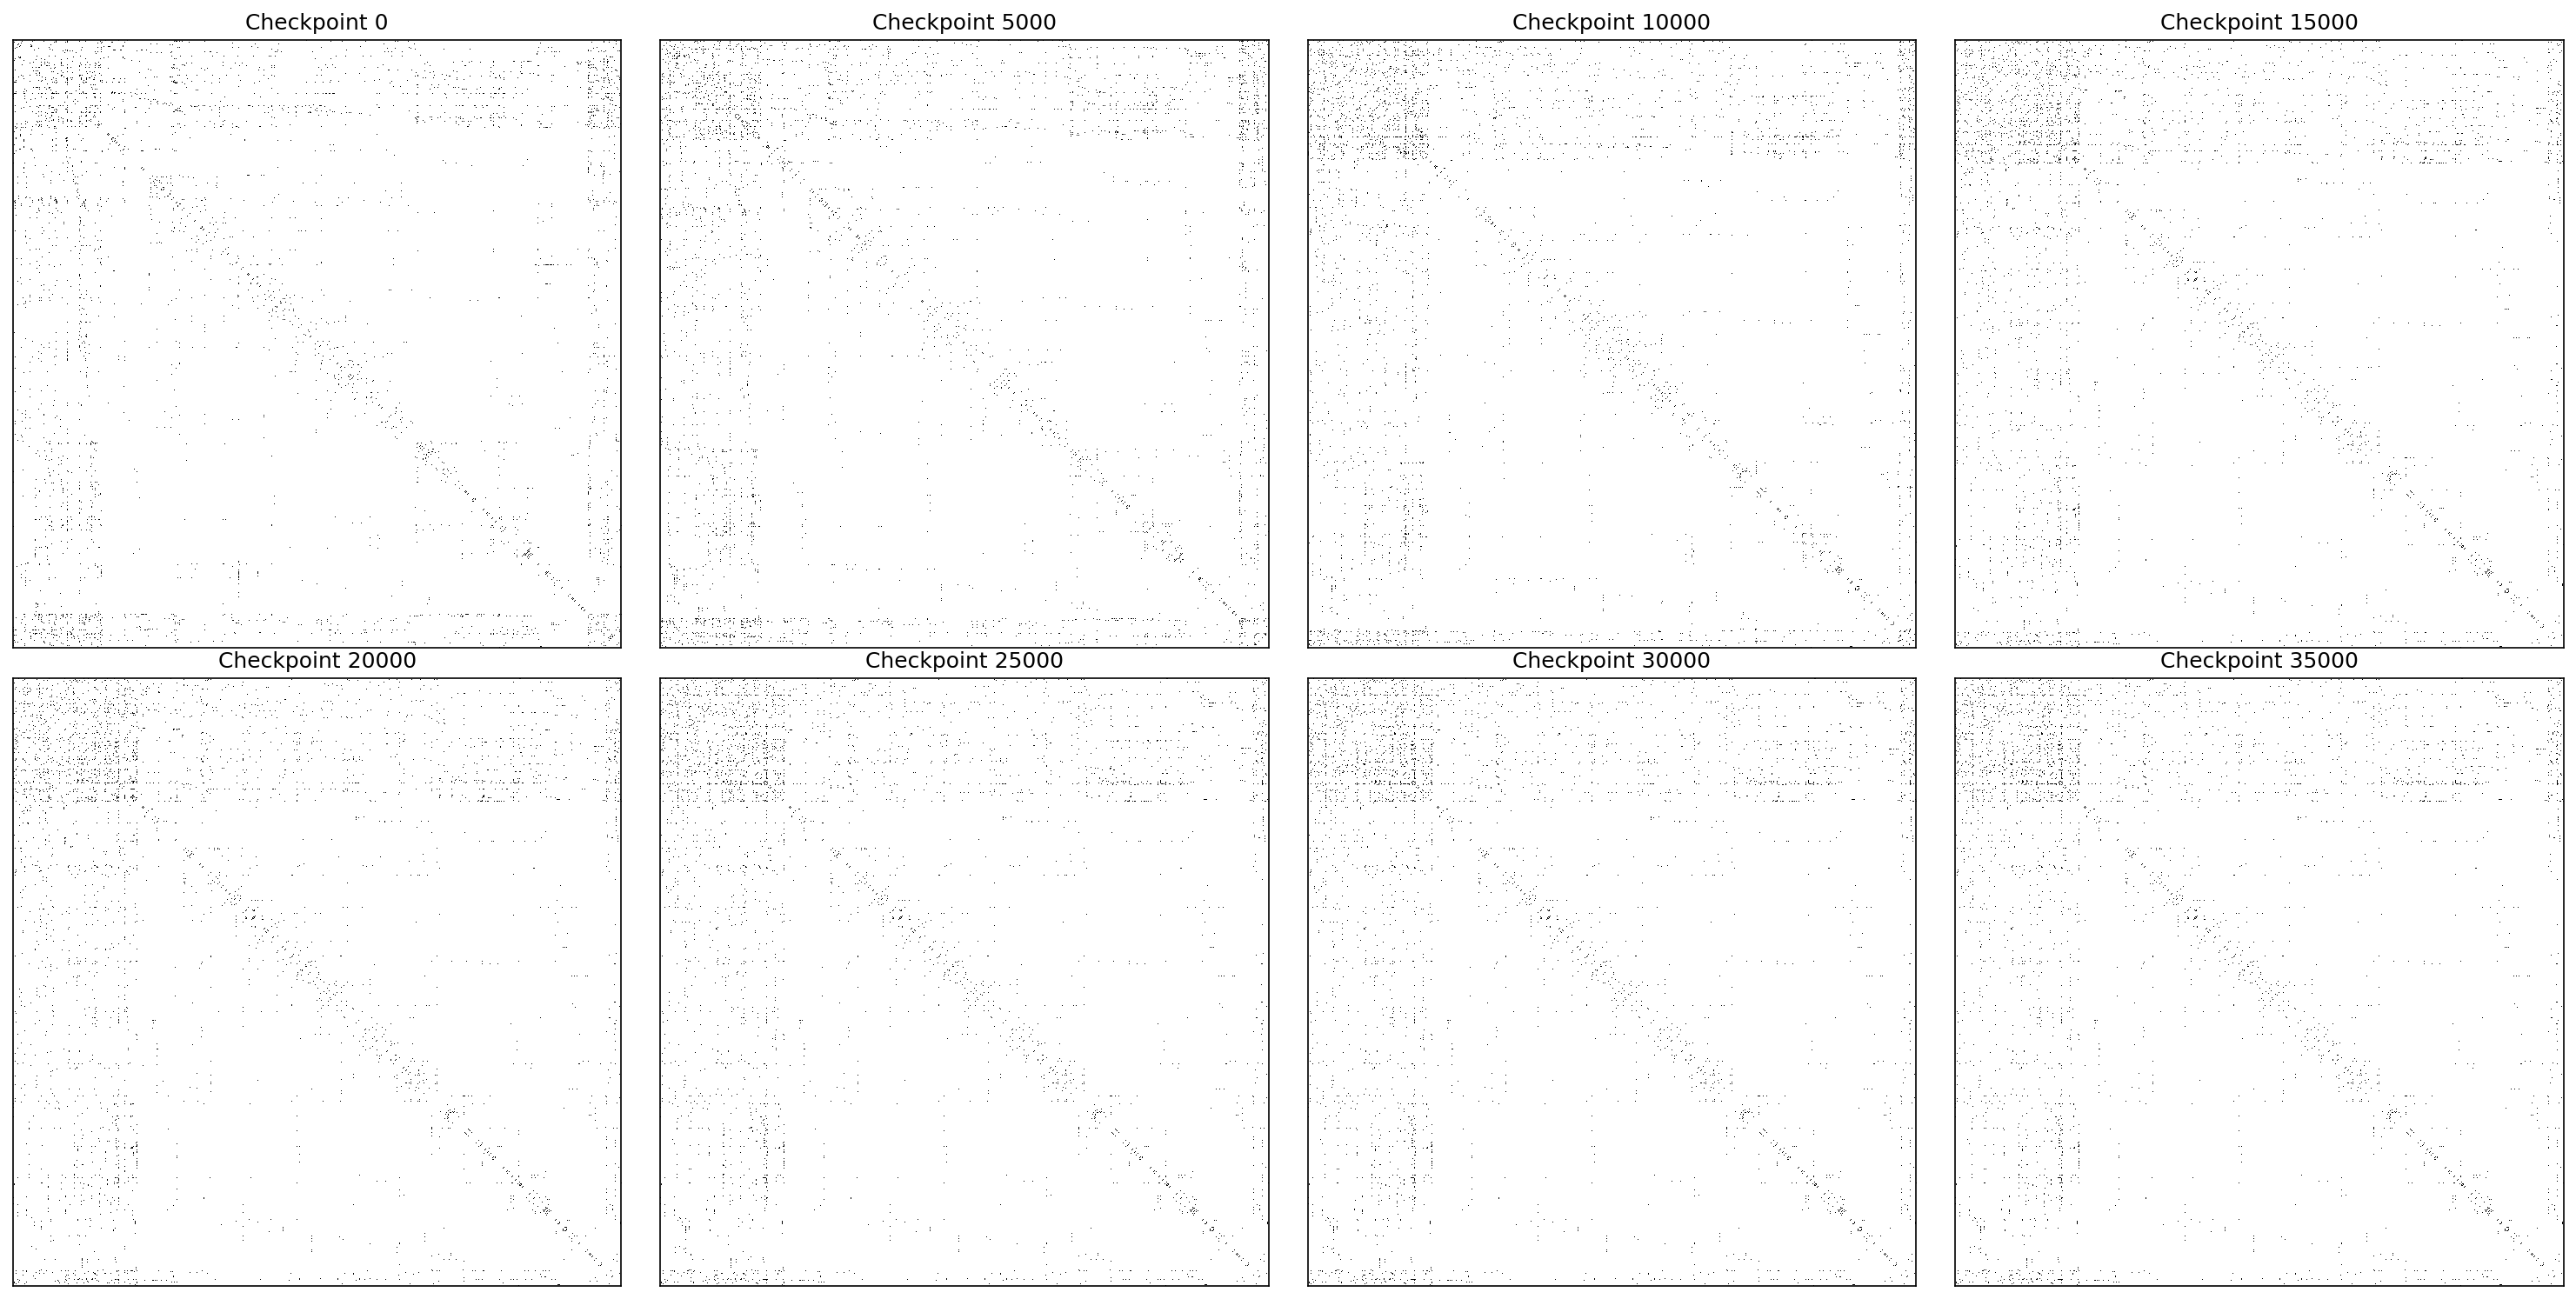

In [11]:
plt.figure(figsize=(20, 10), dpi=150)
sorted_items = sorted(contactomes.items(), key=lambda x: int(x[0].split("_")[-1]))
for i, (cv_channel, G) in enumerate(sorted_items, 1):
    plt.subplot(2, 4, i)
    plt.imshow(nx.to_numpy_array(G) > 0, interpolation="none", cmap="Greys")
    plt.title(f"Checkpoint {cv_channel.split('_')[-1]}")
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()

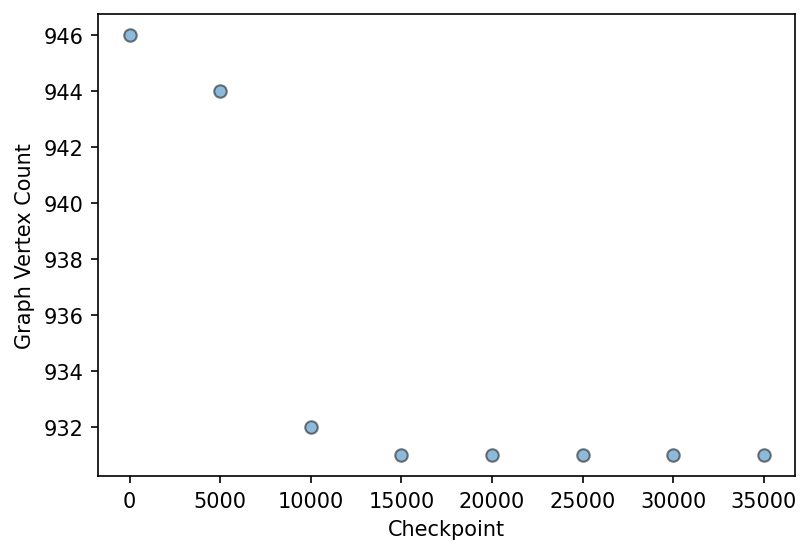

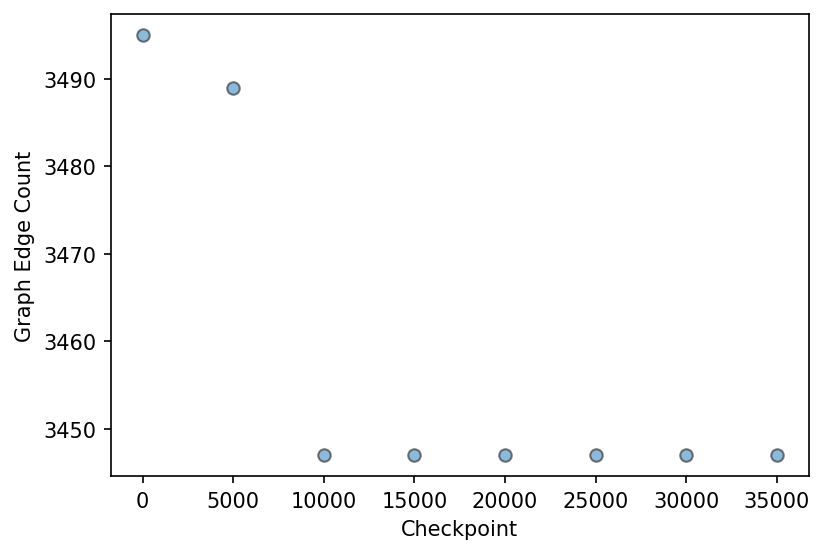

In [9]:
plt.figure(figsize=(6, 4), dpi=150)
plt.scatter(
    [int(cv_channel.split("_")[-1]) for cv_channel, _ in sorted_items],
    [len(g.nodes()) for _, g in sorted_items],
    alpha=0.5,
    edgecolors="k",
)
plt.xlabel("Checkpoint")
plt.ylabel("Graph Vertex Count")
plt.show()

plt.figure(figsize=(6, 4), dpi=150)
plt.scatter(
    [int(cv_channel.split("_")[-1]) for cv_channel, _ in sorted_items],
    [len(g.edges()) for _, g in sorted_items],
    alpha=0.5,
    edgecolors="k",
)
plt.xlabel("Checkpoint")
plt.ylabel("Graph Edge Count")
plt.show()

Text(0, 0.5, 'Graph Density')

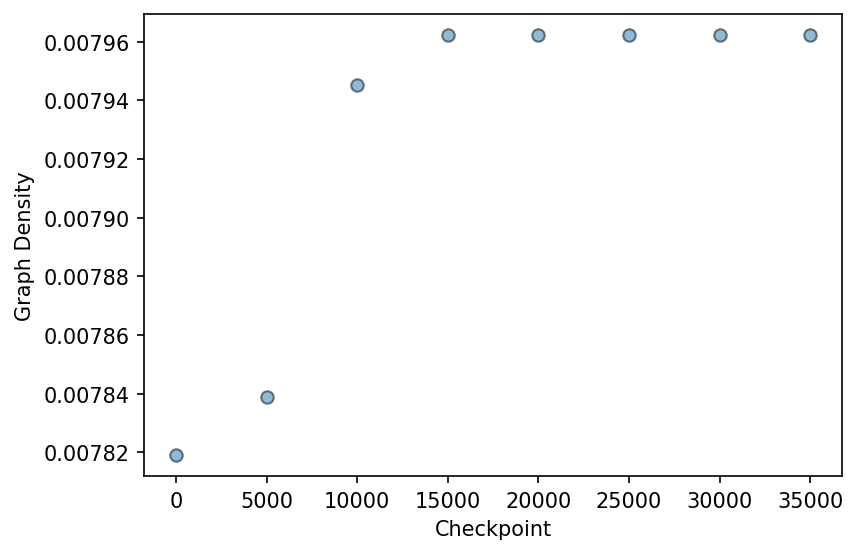

In [17]:
plt.figure(figsize=(6, 4), dpi=150)
plt.scatter(
    [int(cv_channel.split('_')[-1]) for cv_channel, _ in sorted_items],
    [nx.density(g) for _, g in sorted_items],
    alpha=0.5,
    edgecolors="k",
)
plt.xlabel('Checkpoint')
plt.ylabel('Graph Density')
